# Stage 9: Model evaluation on the untouched test set
This is the first and only time the test split is used. We report:
- **Threshold-independent metrics:** ROC-AUC, Gini, KS, PR-AUC, Brier score
- **Threshold-dependent metrics:** accuracy, precision, recall, F1, specificity, confusion matrix
- **Credit-risk views:** calibration, score separation, decile (gains) table, bootstrap confidence intervals

**Metric glossary for interviews**
| Metric | Plain-English meaning in lending |
|---|---|
| Recall (sensitivity) | Share of actual defaulters the model would decline |
| Specificity | Share of good borrowers the model would approve |
| Precision | Of the applicants we decline, how many really would have defaulted |
| ROC-AUC | Probability a random defaulter scores riskier than a random good borrower |
| Gini | 2×AUC − 1, the number credit teams report (0 = random, 1 = perfect) |
| KS | Maximum gap between the cumulative score distributions of goods and bads |
| PR-AUC | Precision/recall trade-off; baseline = default rate, not 0.5 |
| Brier | Mean squared error of the PD; checks calibration |

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from credit_risk.artifacts import load_split_frames, read_json, write_json
from credit_risk.config import get_paths, load_config
from credit_risk.evaluation import (
    classification_metrics,
    compare_models,
    decile_table,
    plot_calibration,
    plot_confusion,
    plot_gains,
    plot_pr_curves,
    plot_roc_curves,
    plot_score_distributions,
)
from credit_risk.modeling import MODEL_LABELS, CreditRiskModel
from credit_risk.thresholds import threshold_sweep
from credit_risk.viz import savefig, set_style

cfg = load_config()
paths = get_paths(cfg)
set_style()
ID, TARGET = cfg["data"]["id_column"], cfg["data"]["target"]

train, valid, test = load_split_frames(paths)
registry = read_json(paths["models"] / "model_registry.json")
models = {n: CreditRiskModel.load(paths["models"] / f"{n}.joblib") for n in registry["candidates"]}
champion_name = registry["champion"]
y_test = test[TARGET].to_numpy()
print(f"Test set: {len(test):,} applicants, default rate {y_test.mean():.2%} | champion: {registry['champion_label']}")

Test set: 46,127 applicants, default rate 8.07% | champion: LightGBM


## 1. Threshold-independent comparison

In [2]:
test_preds = {MODEL_LABELS.get(n, n): (y_test, m.predict_pd(test)) for n, m in models.items()}
metrics_free = compare_models(test_preds)[["roc_auc", "gini", "ks", "pr_auc", "brier"]]
metrics_free.round(4)

,roc_auc,gini,ks,pr_auc,brier
model,,,,,
XGBoost,0.7924,0.5848,0.4479,0.2919,0.0654
LightGBM,0.7923,0.5846,0.4446,0.2944,0.0654
Logistic Regression,0.7779,0.5558,0.4212,0.2702,0.0665
Random Forest,0.7695,0.5390,0.4107,0.2549,0.0672


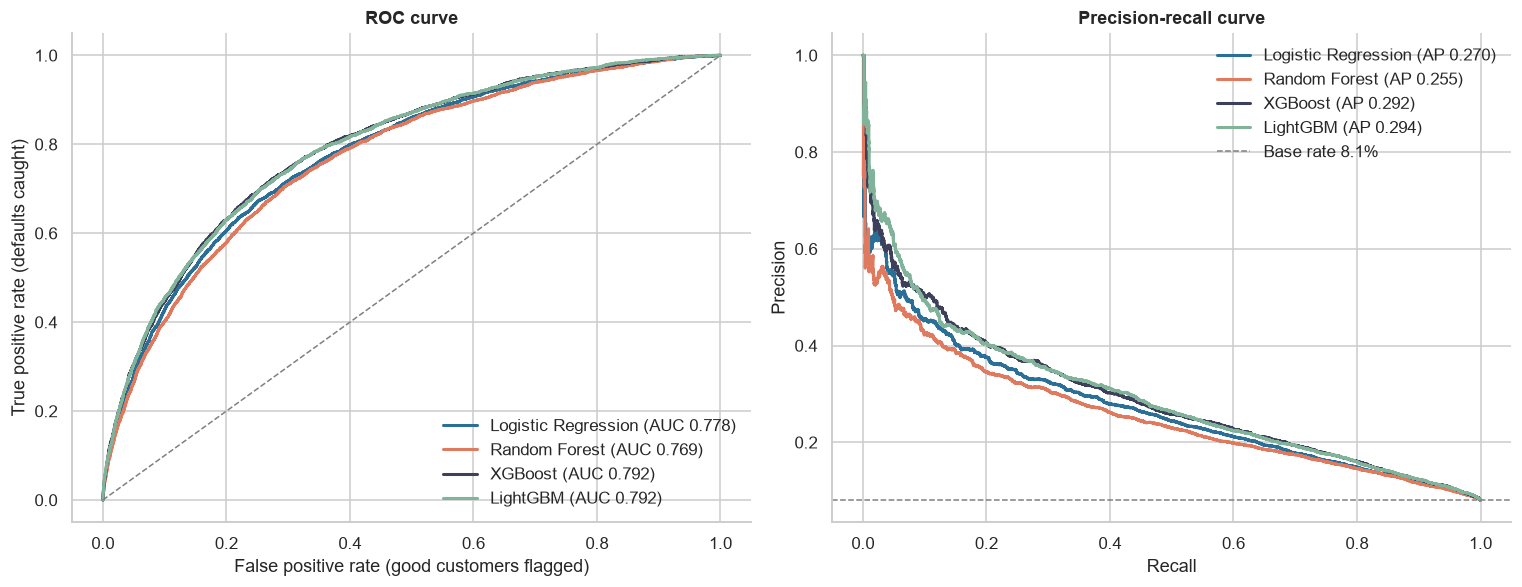

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_roc_curves(test_preds, ax=axes[0])
plot_pr_curves(test_preds, ax=axes[1])
fig.tight_layout()
savefig(fig, "eval_roc_pr_test")
plt.show()

## 2. How uncertain is the AUC? (bootstrap 95% CI)
Two models whose intervals overlap heavily are not meaningfully different. Worth saying in an interview.

In [4]:
rng = np.random.default_rng(0)
N_BOOT = 200
ci = {}
for label, (y, p) in test_preds.items():
    aucs = []
    for _ in range(N_BOOT):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() != y[idx].max():
            aucs.append(roc_auc_score(y[idx], p[idx]))
    ci[label] = {"auc": roc_auc_score(y, p), "ci_low": np.percentile(aucs, 2.5), "ci_high": np.percentile(aucs, 97.5)}
pd.DataFrame(ci).T.round(4)

,auc,ci_low,ci_high
Logistic Regression,0.7779,0.7683,0.7859
Random Forest,0.7695,0.7608,0.7773
XGBoost,0.7924,0.7829,0.7987
LightGBM,0.7923,0.7852,0.7997


## 3. Threshold-dependent metrics: why 0.5 is the wrong cutoff
Our PDs are **calibrated**, so they cluster near the true default rate. Few applicants exceed 0.5, which means a 0.5
cutoff approves nearly everyone: high accuracy, near-zero recall. For comparison we also show each model at the
cutoff that maximised F1 **on the validation set** (chosen without looking at test).

In [5]:
rows = []
for n, m in models.items():
    label = MODEL_LABELS.get(n, n)
    p_valid = m.predict_pd(valid)
    sweep = threshold_sweep(valid[TARGET], p_valid, valid["AMT_CREDIT"], cfg["business"]["lgd"], cfg["business"]["profit_margin"])
    t_f1 = float(sweep.loc[sweep["f1"].idxmax(), "threshold"])
    for tag, t in [("0.50", 0.5), ("F1-optimal (valid)", t_f1)]:
        rows.append({"model": label, "cutoff": tag, **classification_metrics(y_test, test_preds[label][1], t)})
threshold_metrics = pd.DataFrame(rows).set_index(["model", "cutoff"])
threshold_metrics[["threshold", "accuracy", "precision", "recall", "specificity", "f1", "tp", "fp", "fn", "tn"]].round(3)

threshold  accuracy  precision  \
model               cutoff                                               
Logistic Regression 0.50                    0.500     0.920      0.562   
                    F1-optimal (valid)      0.145     0.846      0.256   
Random Forest       0.50                    0.500     0.919      0.552   
                    F1-optimal (valid)      0.160     0.851      0.252   
XGBoost             0.50                    0.500     0.920      0.602   
                    F1-optimal (valid)      0.170     0.864      0.283   
LightGBM            0.50                    0.500     0.920      0.657   
                    F1-optimal (valid)      0.170     0.859      0.277   

                                        recall  specificity     f1    tp  \
model               cutoff                                                 
Logistic Regression 0.50                 0.039        0.997  0.073   145   
                    F1-optimal (valid)   0.477        0.878  0.333  1775   
Random Forest       0.50                 0.010        0.999  0.020    37   
                    F1-optimal (valid)   0.429        0.888  0.318  1598   
XGBoost             0.50                 0.043        0.998  0.080   160   
                    F1-optimal (valid)   0.445        0.901  0.346  1659   
LightGBM            0.50                 0.031        0.999  0.059   115   
                    F1-optimal (valid)   0.464        0.893  0.347  1729   

                                          fp    fn     tn  
model               cutoff                                 
Logistic Regression 0.50                 113  3579  42290  
                    F1-optimal (valid)  5172  1949  37231  
Random Forest       0.50                  30  3687  42373  
                    F1-optimal (valid)  4738  2126  37665  
XGBoost             0.50                 106  3564  42297  
                    F1-optimal (valid)  4205  2065  38198  
LightGBM            0.50                  60  3609  42343  
                    F1-optimal (valid)  4519  1995  37884

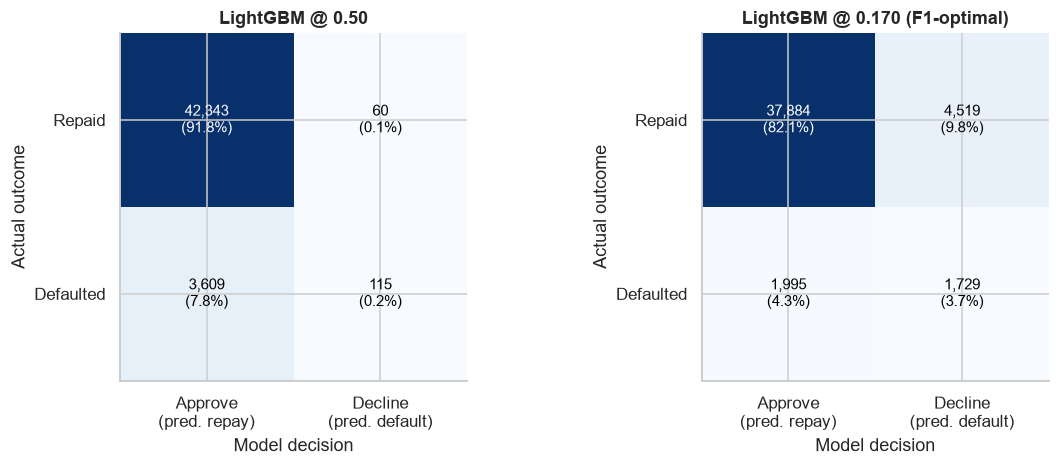

In [6]:
champ_label = registry["champion_label"]
p_champ = test_preds[champ_label][1]
t_f1_champ = threshold_metrics.loc[(champ_label, "F1-optimal (valid)"), "threshold"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
plot_confusion(y_test, p_champ, 0.5, ax=axes[0], title=f"{champ_label} @ 0.50")
plot_confusion(y_test, p_champ, t_f1_champ, ax=axes[1], title=f"{champ_label} @ {t_f1_champ:.3f} (F1-optimal)")
fig.tight_layout()
savefig(fig, "eval_confusion_matrices")
plt.show()

The F1 cutoff is still arbitrary from a business point of view: it treats a false approval and a false rejection
as equally costly. Stage 10 replaces it with a cutoff based on expected profit.

## 4. Calibration: does a 10% PD really mean 10%?

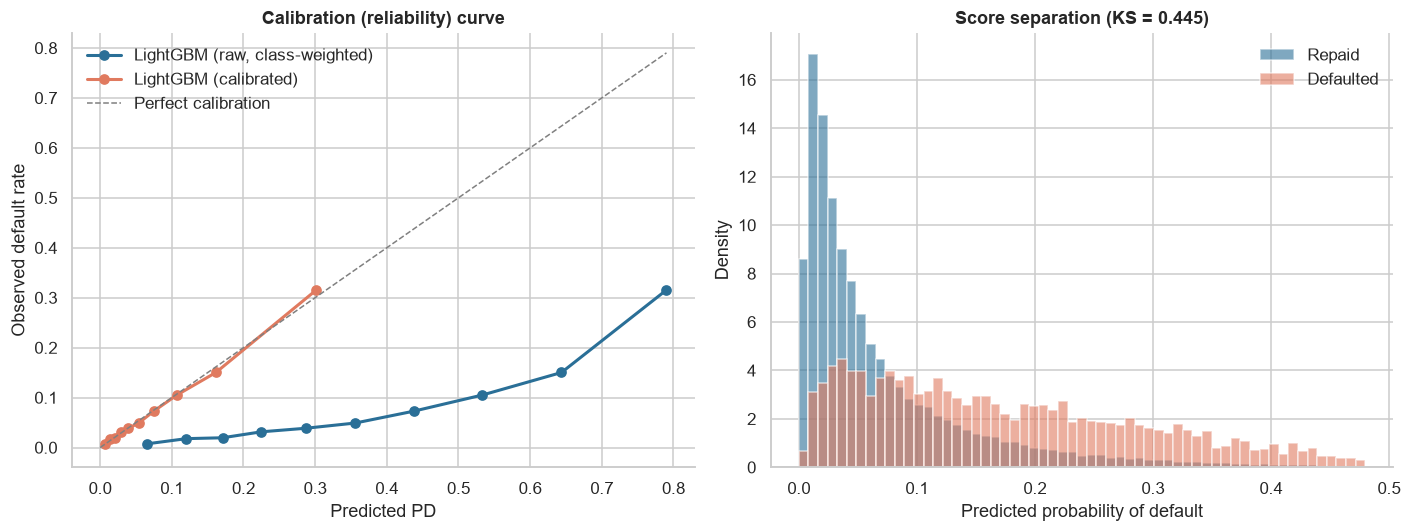

Mean predicted PD 8.074% vs actual default rate 8.073%


In [7]:
champ = models[champion_name]
raw = champ.raw_score(test)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_calibration({f"{champ_label} (raw, class-weighted)": (y_test, raw), f"{champ_label} (calibrated)": (y_test, p_champ)}, ax=axes[0])
plot_score_distributions(y_test, p_champ, ax=axes[1])
fig.tight_layout()
savefig(fig, "eval_calibration_ks")
plt.show()
print(f"Mean predicted PD {p_champ.mean():.3%} vs actual default rate {y_test.mean():.3%}")

## 5. Decile (gains) table: how the business reads a model

,decile,applicants,defaults,min_pd,max_pd,mean_pd,default_rate,cum_defaults_captured,cum_population,lift
0,1,4613,1455,0.204,0.727,0.302,31.54%,39.1%,10%,3.91
1,2,4613,693,0.129,0.204,0.162,15.02%,57.7%,20%,1.86
2,3,4612,485,0.088,0.129,0.107,10.52%,70.7%,30%,1.30
3,4,4613,336,0.063,0.088,0.075,7.28%,79.7%,40%,0.90
4,5,4613,226,0.046,0.063,0.054,4.90%,85.8%,50%,0.61
5,6,4612,178,0.034,0.046,0.039,3.86%,90.6%,60%,0.48
6,7,4613,145,0.024,0.034,0.029,3.14%,94.5%,70%,0.39
7,8,4612,90,0.017,0.024,0.020,1.95%,96.9%,80%,0.24
8,9,4613,82,0.010,0.017,0.013,1.78%,99.1%,90%,0.22
9,10,4613,34,0.001,0.010,0.007,0.74%,100.0%,100%,0.09


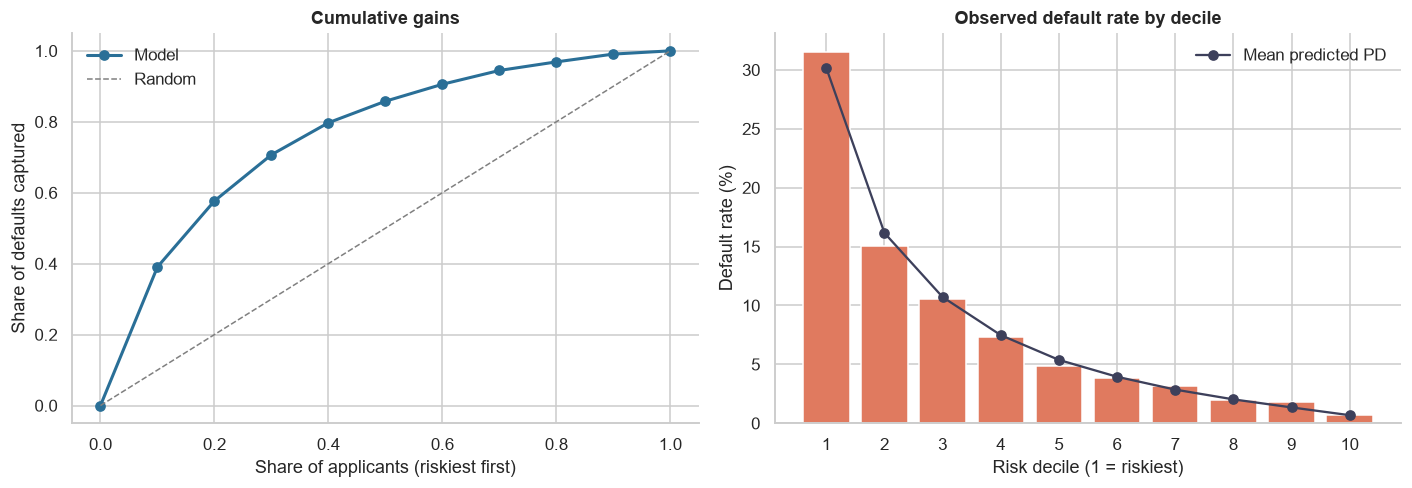

The riskiest 20% of applicants contain 58% of all defaults. Declining them would avoid that share of defaults.


In [8]:
deciles = decile_table(y_test, p_champ)
display(deciles.style.format({"min_pd": "{:.3f}", "max_pd": "{:.3f}", "mean_pd": "{:.3f}", "default_rate": "{:.2%}",
                              "cum_defaults_captured": "{:.1%}", "cum_population": "{:.0%}", "lift": "{:.2f}"}))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
plot_gains(deciles, ax=ax[0])
ax[1].bar(deciles["decile"].astype(str), 100 * deciles["default_rate"], color="#e07a5f")
ax[1].plot(deciles["decile"].astype(str), 100 * deciles["mean_pd"], color="#3d405b", marker="o", label="Mean predicted PD")
ax[1].set(xlabel="Risk decile (1 = riskiest)", ylabel="Default rate (%)", title="Observed default rate by decile")
ax[1].legend(frameon=False)
fig.tight_layout()
savefig(fig, "eval_deciles")
plt.show()
top2 = deciles.loc[1, "cum_defaults_captured"]
print(f"The riskiest 20% of applicants contain {top2:.0%} of all defaults. Declining them would avoid that share of defaults.")

## 6. Save test predictions and metrics

In [9]:
pred_df = pd.DataFrame({ID: test[ID].to_numpy(), TARGET: y_test, "AMT_CREDIT": test["AMT_CREDIT"].to_numpy()})
for n, m in models.items():
    pred_df[f"pd_{n}"] = test_preds[MODEL_LABELS.get(n, n)][1]
pred_df["pd"] = pred_df[f"pd_{champion_name}"]
pred_df.to_parquet(paths["processed_data"] / "test_predictions.parquet", index=False)

summary = {"champion": champion_name, **{k: float(v) for k, v in metrics_free.loc[champ_label].items()},
           "auc_ci_low": float(ci[champ_label]["ci_low"]), "auc_ci_high": float(ci[champ_label]["ci_high"]),
           "test_default_rate": float(y_test.mean()), "mean_pd": float(p_champ.mean())}
write_json(summary, paths["reports"] / "test_metrics.json")
metrics_free.to_csv(paths["reports"] / "model_comparison_test.csv")
deciles.to_csv(paths["reports"] / "decile_table_test.csv", index=False)
pd.Series(summary).to_frame("champion (test)")

,champion (test)
champion,lightgbm
roc_auc,0.792309
gini,0.584618
ks,0.444567
pr_auc,0.294413
brier,0.065359
auc_ci_low,0.785231
auc_ci_high,0.799715
test_default_rate,0.080734
mean_pd,0.080741
